# Catalan's constant $G$: historical constructions and new result

Each section constructs a CMF, walks a trajectory with ramanujantools and prints $\delta_N$ at the deepest sample, where $|G-p_N/q_N|=q_N^{-(1+\delta_N)}$ for the reduced $p_N/q_N$. Run the cells in order with `cmfs.py` next to this notebook. A finite-depth $\delta_N$ does not prove a measure bound.

In [1]:
# @title Install dependencies (run once per environment)
%pip -q install ramanujantools==0.0.8 sympy==1.14.0 matplotlib==3.11.2

## Setup

$(s_0,s_1,\ldots)$ is the first column of the walk.

In [2]:
import sys

import matplotlib.pyplot as plt
import sympy as sp
from flint import arb, ctx
from ramanujantools import Matrix
from ramanujantools.cmf.pfq import pFq

from cmfs import eskandari_catalan

sys.set_int_max_str_digits(0)
with ctx.workdps(162_000):  # q_N reaches about 80,000 digits at depth 3000
    CATALAN = arb.const_catalan()
DEPTHS = list(range(10, 3001, 10))
x0, x1, x2, x3, y0, y1, y2 = sp.symbols("x0 x1 x2 x3 y0 y1 y2")
results = {}
accuracy = {}


def delta(approximant):
    """delta with |G - p/q| = q^-(1 + delta), for the reduced fraction p/q."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):  # enough bits to resolve |G - p/q|
        error = abs(CATALAN - arb(p) / q)
    return float((-1 - error.log() / arb(q).log()).mid())

def correct_digits(approximant):
    """D_N = -log10 |G - p/q|, for the reduced fraction p/q."""
    p, q = int(approximant.p), int(approximant.q)
    with ctx.workprec(2 * q.bit_length() + 64):
        error = abs(CATALAN - arb(p) / q)
    return float((-error.log() / arb(10).log()).mid())

## 1. Nesterenko (2016)

Proc. Steklov Inst. Math. **292** (2016)

${}_3F_2(1)$ · start $(1,1,\tfrac32;\tfrac52,\tfrac52)$ · trajectory $(1,1,1;2,2)$ · $p_N/q_N=(4s_0-5s_1)/(4s_0-6s_1)$

In [3]:
cmf = pFq(3, 2, 1)
start = {x0: 1, x1: 1, x2: sp.Rational(3, 2), y0: sp.Rational(5, 2), y1: sp.Rational(5, 2)}
trajectory = {x0: 1, x1: 1, x2: 1, y0: 2, y1: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(4 * W[0, 0] - 5 * W[1, 0]) / (4 * W[0, 0] - 6 * W[1, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Nesterenko (2016)"] = (DEPTHS, deltas)
accuracy["Nesterenko (2016)"] = [correct_digits(r) for r in approximants]
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: -0.474009495


## 2. Direction search in ${}_3F_2(1)$

${}_3F_2(1)$ · start $(2,2,\tfrac32;\tfrac72,\tfrac72)$ · trajectory $(20,22,25;40,42)$ · $p_N/q_N=(26s_0-59s_1)/(28s_0-66s_1)$

In [4]:
cmf = pFq(3, 2, 1)
start = {x0: 2, x1: 2, x2: sp.Rational(3, 2), y0: sp.Rational(7, 2), y1: sp.Rational(7, 2)}
trajectory = {x0: 20, x1: 22, x2: 25, y0: 40, y1: 42}
depths = list(range(10, 1501, 10))  # q_N reaches about 105,000 digits at depth 1500
walks = cmf.walk(trajectory, depths, start)
approximants = [(26 * W[0, 0] - 59 * W[1, 0]) / (28 * W[0, 0] - 66 * W[1, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["Direction search in 3F2(1)"] = (depths, deltas)
accuracy["Direction search in 3F2(1)"] = [correct_digits(r) for r in approximants]
print(f"delta at depth 1500: {deltas[-1]:.9f}")

delta at depth 1500: -0.431308830


## 3. New best trajectory

${}_4F_3(1)$, dual · start $(4,4,-\tfrac12,0;\tfrac72,\tfrac72,4)$ · trajectory $(11,9,-2,-11;-1,0,2)$ · $p_N/q_N=(4915s_1+754s_2)/(6930s_1+1260s_2)$

The paper proves $\liminf_N\delta_N>-0.295976878$ for this trajectory (error power
$0.704023122$); the gap to the numerical value below needs further common factors
of $p_N$ and $q_N$.

In [5]:
cmf = pFq(4, 3, 1).dual()  # inverse-transpose matrices
start = {x0: 4, x1: 4, x2: -sp.Rational(1, 2), x3: 0, y0: sp.Rational(7, 2), y1: sp.Rational(7, 2), y2: 4}
trajectory = {x0: 11, x1: 9, x2: -2, x3: -11, y0: -1, y1: 0, y2: 2}
walks = cmf.walk(trajectory, DEPTHS, start)
approximants = [(4915 * W[1, 0] + 754 * W[2, 0]) / (6930 * W[1, 0] + 1260 * W[2, 0]) for W in walks]
deltas = [delta(r) for r in approximants]
results["New best trajectory"] = (DEPTHS, deltas)
accuracy["New best trajectory"] = [correct_digits(r) for r in approximants]
print(f"delta at depth 3000: {deltas[-1]:.9f}")

delta at depth 3000: -0.274977139


## 4. Eskandari (2026)

[arXiv:2609.26354](https://arxiv.org/html/2609.26354v1) · on $(3,10)$, $\liminf_N\delta_N\ge-0.3768$

Rank-8 CMF of the binomial transforms $\sum_i\binom mi(-16)^iu_{k+i}$ of Eskandari's sequences (`eskandari_catalan`) · start $(0,0)$ · trajectory $(3,10)$ · $p_N/q_N=(V_0W)_0/(U_0W)_0$, with $U_0,V_0$ the first eight terms of $u,v$

In [6]:
k, m = sp.symbols("k m")
cmf = eskandari_catalan()
start = {k: 0, m: 0}
trajectory = {k: 3, m: 10}
depths = list(range(10, 101, 10))
walks = cmf.walk(trajectory, depths, start)
R = sp.Rational
U0 = Matrix([[8, -14, R(649, 8), R(-19471, 32), R(10439881, 2048), R(-372106183, 8192),
              R(55182648049, 131072), R(-2102590888447, 524288)]])  # u_0, ..., u_7
V0 = Matrix([[0, -13, R(10699, 144), R(-8025653, 14400), R(210854706467, 45158400),
              R(-67638995691893, 1625702400), R(1213719058519951259, 3147359846400),
              R(-7815506292703811398013, 2127615256166400)]])  # v_0, ..., v_7
approximants = [(V0 * W)[0] / (U0 * W)[0] for W in walks]
deltas = [delta(r) for r in approximants]
results["Eskandari (2026)"] = (depths, deltas)
accuracy["Eskandari (2026)"] = [correct_digits(r) for r in approximants]
print(f"delta at depth 100: {deltas[-1]:.9f}")

delta at depth 100: -0.373117788


## All constructions

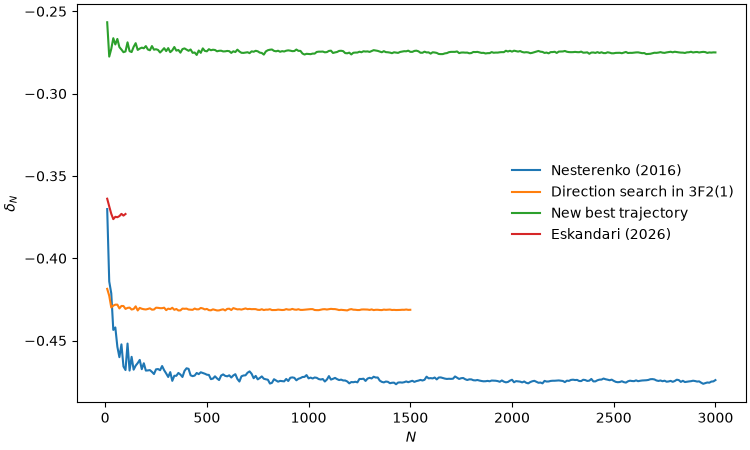

In [7]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(depths, values, label=name)
ax.set(xlabel="$N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## $\delta_N$ against accuracy digits

The same samples against $D_N$ instead of $N$, as in the paper's figure of
$\delta_N$ against accuracy digits.

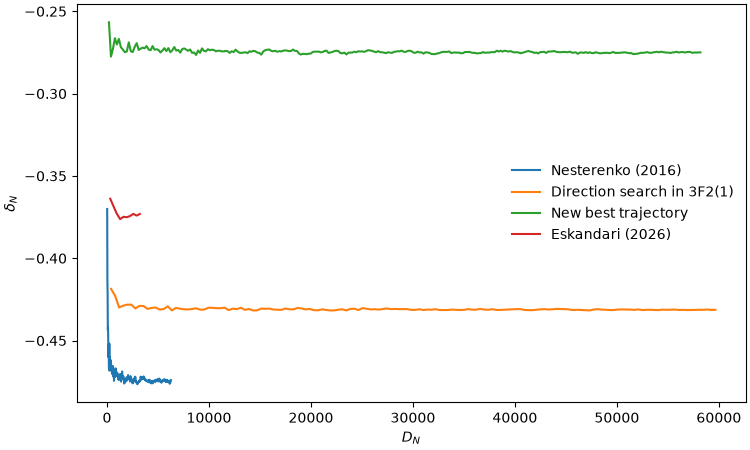

In [8]:
fig, ax = plt.subplots(figsize=(7.5, 4.5), constrained_layout=True)
for name, (depths, values) in results.items():
    ax.plot(accuracy[name], values, label=name)
ax.set(xlabel="$D_N$", ylabel=r"$\delta_N$")
ax.legend(frameon=False)
plt.show()

## Historical overview

| Construction | Reported | Here |
|:--|--:|:--|
| Nesterenko (2016) | — | CMF |
| [Viola–Marcovecchio (2022)](https://doi.org/10.4171/OWR/2022/21) | error power $0.6293$, $\delta\ge-0.3707$ | reference only |
| [Ramanujan Machine (2021), SI Table 6](https://static-content.springer.com/esm/art%3A10.1038%2Fs41586-021-03229-4/MediaObjects/41586_2021_3229_MOESM1_ESM.pdf) | $0.475, 0.486, 0.510, 0.462, 0.4325$ | reference only |
| Eskandari (2026) | $\kappa\ge0.62$ | CMF |
| This work, ${}_3F_2(1)$ direction search | — | CMF |
| This work, ${}_4F_3(1)$ | proved $\delta>-0.295976878$ | CMF |